# RQ3 Analysis: Lexical Density

Compares lexical density of human-written PR descriptions and AI-generated descriptions across six context variations.

- Models: `meta-llama/llama-3.1-70b-instruct`, `gpt-5-mini-2025-08-07`, `Qwen/Qwen2.5-72B-Instruct`
- Formula: `Lexical Density = content_words / total_tokens`
- Content POS tags: `NOUN`, `PROPN`, `VERB`, `ADJ`, `ADV`
- POS tagging: spaCy `en_core_web_sm`

In [1]:
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt_tab', quiet=True)


en_core_web_sm already installed


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from pathlib import Path
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
CONTEXT_MAPPING = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'PR Diffs',
    'P-4': 'File Contents',
    'P-5': 'Related Issues',
    'P-6': 'Without File Contents'
}

TARGET_MODELS = [
    'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct'
 ]

csv_path = Path('..') / 'datasets' / 'temperature_1' / 'run_3' / 'detection_results.csv'
df = pd.read_csv(csv_path, usecols=['pr_id', 'entry_type', 'variation', 'model', 'text']).copy()

# Normalize model names to canonical labels used in this notebook
model_aliases = {
    'meta-llama_llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'meta-llama/llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07': 'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen/Qwen2.5-72B-Instruct'
}
df['model'] = df['model'].astype(str).str.strip().map(lambda m: model_aliases.get(m, m))

ai_df = df[(df['entry_type'] == 'ai') & (df['model'].isin(TARGET_MODELS))].copy()
ai_df = ai_df[ai_df['variation'].isin(CONTEXT_MAPPING.keys())].copy()
ai_df['context_level'] = ai_df['variation']
ai_df['Context_Name'] = ai_df['variation'].map(CONTEXT_MAPPING)
ai_df['normalized_pr_id'] = ai_df['pr_id'].astype(str).str.strip()

human_df = df[df['entry_type'] == 'human'].copy()
human_df['model'] = 'Human'
human_df['context_level'] = 'Original'
human_df['Context_Name'] = 'Original'
human_df['normalized_pr_id'] = human_df['pr_id'].astype(str).str.strip()

valid_ids = set(ai_df['normalized_pr_id']).intersection(set(human_df['normalized_pr_id']))
ai_df = ai_df[ai_df['normalized_pr_id'].isin(valid_ids)].copy()
human_df = human_df[human_df['normalized_pr_id'].isin(valid_ids)].copy()

print(f'Data source: {csv_path}')
print(f'Paired PR count: {len(valid_ids)}')
print('Models found:', sorted(ai_df['model'].unique().tolist()))
print('Contexts found:', sorted(ai_df['variation'].unique().tolist()))
print(f'Human rows: {len(human_df)}, AI rows: {len(ai_df)}')

Data source: ../datasets/temperature_1/run_3/detection_results.csv
Paired PR count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
Contexts found: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Human rows: 308, AI rows: 5528


## 2. Compute Lexical Density (NLTK POS)


In [4]:
# Penn Treebank tags corresponding to spaCy's NOUN, PROPN, VERB, ADJ, ADV
CONTENT_POS = {
    'NN', 'NNS', 'NNP', 'NNPS',  # NOUN / PROPN
    'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',  # VERB
    'JJ', 'JJR', 'JJS',  # ADJ
    'RB', 'RBR', 'RBS',  # ADV
}

def lexical_density(text: str) -> float:
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    tokens = [tok for tok in nltk.word_tokenize(str(text)) if tok.isalpha()]
    if len(tokens) == 0:
        return np.nan
    tagged = nltk.pos_tag(tokens)
    content_words = sum(1 for _, pos in tagged if pos in CONTENT_POS)
    return content_words / len(tokens)

human_df['lexical_density'] = human_df['text'].apply(lexical_density)
ai_df['lexical_density'] = ai_df['text'].apply(lexical_density)
human_df['source'] = 'Human'
ai_df['source'] = 'AI'
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
print(f'Computed lexical density: human={len(human_df)}, ai={len(ai_df)}')


Lexical density computed.


,entry_type,model,context_level,lexical_density
0,human,Human,Original,0.518868
1,human,Human,Original,0.714286
2,human,Human,Original,0.541667
3,human,Human,Original,0.666667
4,human,Human,Original,1.000000
5,human,Human,Original,0.564286
6,human,Human,Original,0.570000
7,human,Human,Original,0.666667
8,human,Human,Original,0.629032
9,human,Human,Original,0.565217


## 3. Descriptive Statistics

In [33]:
overall_stats = combined_df.groupby('source')['lexical_density'].describe()
overall_stats['median'] = combined_df.groupby('source')['lexical_density'].median()
display(overall_stats)

model_stats = ai_df.groupby('model')['lexical_density'].describe()
model_stats['median'] = ai_df.groupby('model')['lexical_density'].median()
display(model_stats)

context_stats = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].describe()
context_stats['median'] = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].median()
display(context_stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,0.658010,0.070770,0.441176,0.608081,0.654762,0.705374,1.0,0.654762
Human,308.0,0.604092,0.097581,0.400000,0.540803,0.585136,0.643776,1.0,0.585136


,count,mean,std,min,25%,50%,75%,max,median
model,,,,,,,,,
Qwen/Qwen2.5-72B-Instruct,1842.0,0.611403,0.047838,0.441176,0.578125,0.611111,0.643323,0.759259,0.611111
gpt-5-mini-2025-08-07,1842.0,0.693981,0.048428,0.540541,0.661172,0.694915,0.727192,0.848485,0.694915
meta-llama/llama-3.1-70b-instruct,1844.0,0.668635,0.082546,0.448980,0.611111,0.666667,0.722222,1.000000,0.666667


count      mean  \
model                             Context_Name                             
Qwen/Qwen2.5-72B-Instruct         File Contents          302.0  0.645225   
                                  PR Diffs               308.0  0.609182   
                                  PR Title               308.0  0.622963   
                                  Related Issues         308.0  0.575130   
                                  Repo Path              308.0  0.621120   
                                  Without File Contents  308.0  0.595456   
gpt-5-mini-2025-08-07             File Contents          302.0  0.724327   
                                  PR Diffs               308.0  0.699158   
                                  PR Title               308.0  0.690636   
                                  Related Issues         308.0  0.656604   
                                  Repo Path              308.0  0.708410   
                                  Without File Contents  308.0  0.685342   
meta-llama/llama-3.1-70b-instruct File Contents          304.0  0.705517   
                                  PR Diffs               308.0  0.693187   
                                  PR Title               308.0  0.646689   
                                  Related Issues         308.0  0.631816   
                                  Repo Path              308.0  0.717238   
                                  Without File Contents  308.0  0.617840   

                                                              std       min  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.041783  0.511628   
                                  PR Diffs               0.043184  0.493506   
                                  PR Title               0.046921  0.490566   
                                  Related Issues         0.042097  0.441176   
                                  Repo Path              0.039253  0.523810   
                                  Without File Contents  0.041208  0.506849   
gpt-5-mini-2025-08-07             File Contents          0.046823  0.562500   
                                  PR Diffs               0.051767  0.542857   
                                  PR Title               0.038178  0.595745   
                                  Related Issues         0.040405  0.540541   
                                  Repo Path              0.037973  0.602041   
                                  Without File Contents  0.045535  0.573333   
meta-llama/llama-3.1-70b-instruct File Contents          0.076640  0.500000   
                                  PR Diffs               0.072122  0.500000   
                                  PR Title               0.064678  0.448980   
                                  Related Issues         0.073401  0.472222   
                                  Repo Path              0.088963  0.500000   
                                  Without File Contents  0.060559  0.486486   

                                                              25%       50%  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.619789  0.643521   
                                  PR Diffs               0.579922  0.607976   
                                  PR Title               0.590909  0.625000   
                                  Related Issues         0.545455  0.575171   
                                  Repo Path              0.592404  0.617647   
                                  Without File Contents  0.565833  0.593387   
gpt-5-mini-2025-08-07             File Contents          0.694144  0.726785   
                                  PR Diffs               0.666667  0.702836   
                                  PR Title               0.663043  0.691948   
                                  Related Issues         0.629292  0.656627   
       

## 4. Statistical Testing & Effect Size

In [34]:
def cliffs_delta(a, b):
    m, n = len(a), len(b)
    if m == 0 or n == 0:
        return 0.0
    score = 0
    for x in a:
        for y in b:
            if x > y:
                score += 1
            elif x < y:
                score -= 1
    return score / (m * n)

def interpret_cd(d):
    ad = abs(d)
    if ad < 0.147:
        return 'Negligible'
    if ad < 0.33:
        return 'Small'
    if ad < 0.474:
        return 'Medium'
    return 'Large'

human_vals = human_df['lexical_density'].dropna().values
ai_vals = ai_df['lexical_density'].dropna().values
u_stat, p_val = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())
print(f'Human vs AI: U={u_stat:.2f}, p={p_val:.6g}, Cliff\'s d={cd:.4f} ({interpret_cd(cd)})')

# Human vs each LLM (reference-style output table)
model_results = []
for model in TARGET_MODELS:
    model_slice = ai_df[ai_df['model'] == model]
    ids = set(model_slice['normalized_pr_id'])

    human_model_vals = human_df[human_df['normalized_pr_id'].isin(ids)]['lexical_density'].dropna().values
    model_vals = model_slice['lexical_density'].dropna().values

    if len(human_model_vals) == 0 or len(model_vals) == 0:
        continue

    stat, p = mannwhitneyu(human_model_vals, model_vals, alternative='two-sided')
    d = cliffs_delta(human_model_vals.tolist(), model_vals.tolist())

    model_results.append({
        'Model': model,
        'Metric': 'Lexical Density',
        'Human Mean': np.mean(human_model_vals),
        'Model Mean': np.mean(model_vals),
        'Human Median': np.median(human_model_vals),
        'Model Median': np.median(model_vals),
        'U-Statistic': stat,
        'p-value': p,
        'Significant': 'Yes' if p < 0.05 else 'No',
        "Cliff's Delta": round(d, 4),
        'Effect Size': interpret_cd(d)
    })

model_results_df = pd.DataFrame(model_results)
display(model_results_df)

groups = [ai_df[ai_df['model'] == model]['lexical_density'].dropna().values for model in TARGET_MODELS]
h_stat, h_p = kruskal(*groups)
print(f'Kruskal-Wallis across models: H={h_stat:.4f}, p={h_p:.6g}')

dunn_models = sp.posthoc_dunn(ai_df[['model', 'lexical_density']].dropna(), val_col='lexical_density', group_col='model', p_adjust='bonferroni')
display(dunn_models)

Human vs AI: U=449212.50, p=2.28614e-44, Cliff's d=-0.4723 (Medium)


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,Lexical Density,0.604092,0.668635,0.585136,0.666667,144348.5,1.590893e-43,Yes,-0.4917,Large
1,gpt-5-mini-2025-08-07,Lexical Density,0.604092,0.693981,0.585136,0.694915,76715.5,1.365033e-93,Yes,-0.7296,Large
2,Qwen/Qwen2.5-72B-Instruct,Lexical Density,0.604092,0.611403,0.585136,0.611111,228148.5,3.680125e-08,Yes,-0.1957,Small


Kruskal-Wallis across models: H=1535.0605, p=0


,Qwen/Qwen2.5-72B-Instruct,gpt-5-mini-2025-08-07,meta-llama/llama-3.1-70b-instruct
Qwen/Qwen2.5-72B-Instruct,1.000000e+00,0.000000e+00,1.275674e-129
gpt-5-mini-2025-08-07,0.000000e+00,1.000000e+00,2.903801e-47
meta-llama/llama-3.1-70b-instruct,1.275674e-129,2.903801e-47,1.000000e+00


## 5. Visualizations

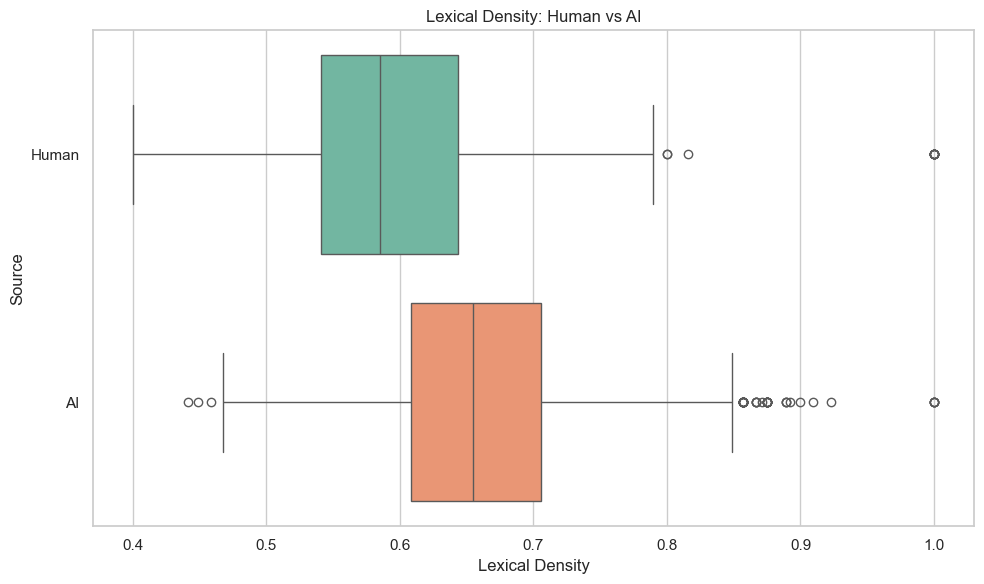

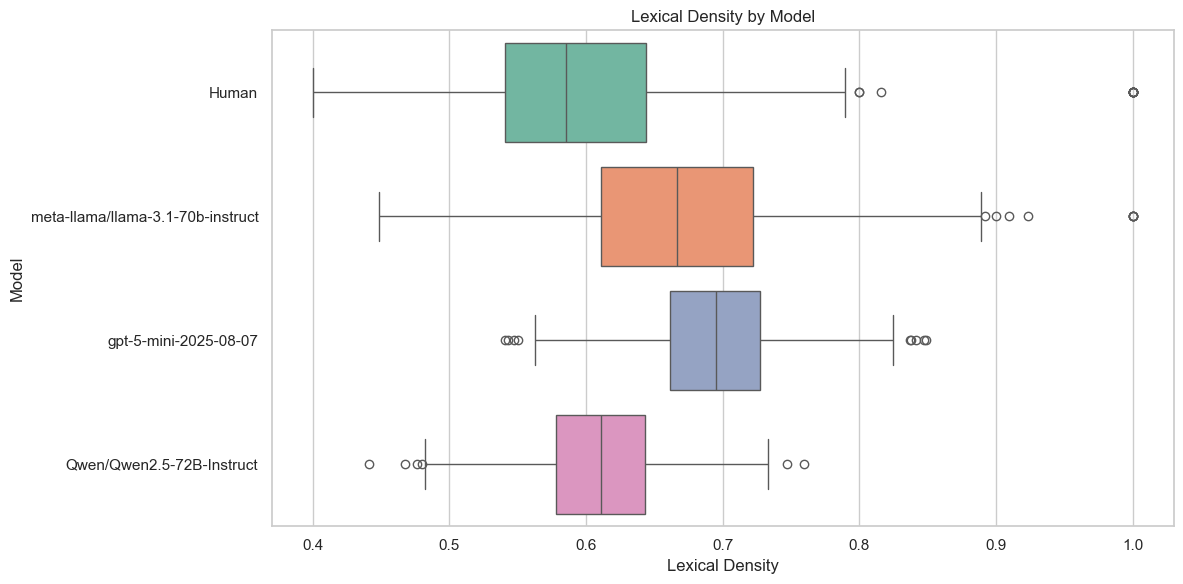

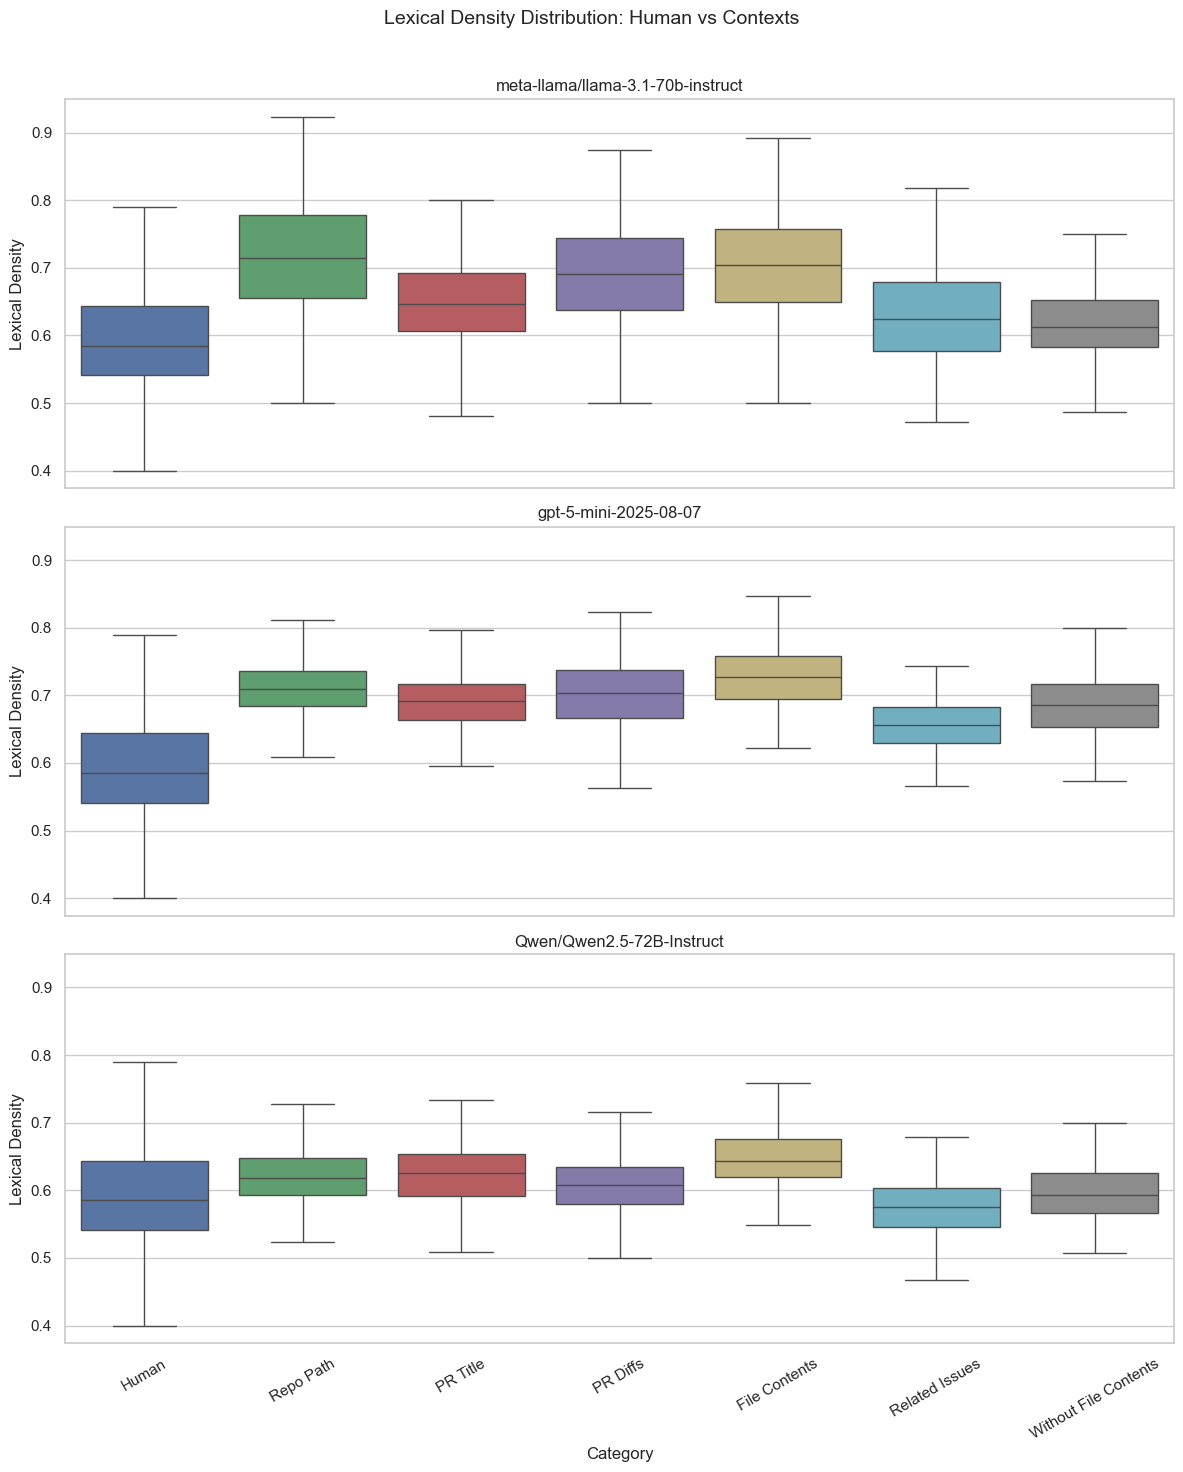

In [5]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='lexical_density', y='source', hue='source', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=14)
plt.ylabel('Source', fontsize=14)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
model_plot_df = combined_df.copy()
order = ['Human'] + TARGET_MODELS
sns.boxplot(data=model_plot_df, x='lexical_density', y='model', order=order, hue='model', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=14)
plt.ylabel('Model', fontsize=14)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

# Context comparison in the same style as other RQ3 notebooks:
# one panel per LLM (stacked vertically) with a Human baseline in each panel.
context_order = [CONTEXT_MAPPING[k] for k in ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']]
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    context_order[0]: '#55A868',
    context_order[1]: '#C44E52',
    context_order[2]: '#8172B2',
    context_order[3]: '#CCB974',
    context_order[4]: '#64B5CD',
    context_order[5]: '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    ai_slice = ai_df[ai_df['model'] == model][['lexical_density', 'Context_Name']].dropna().copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['lexical_density']].dropna().copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['lexical_density', 'Category']],
        ai_slice[['lexical_density', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='lexical_density',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('Lexical Density', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=12)

plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 6. Human vs AI Context Variations (Cliff's δ per Model)

In [36]:
rows = []
for model in TARGET_MODELS:
    model_slice = ai_df[ai_df['model'] == model]
    row = {'Model': model}
    for p_code, ctx_name in CONTEXT_MAPPING.items():
        ai_ctx = model_slice[model_slice['variation'] == p_code]
        ids = set(ai_ctx['normalized_pr_id'])
        human_ctx = human_df[human_df['normalized_pr_id'].isin(ids)]

        ai_vals = ai_ctx['lexical_density'].dropna().values
        human_vals = human_ctx['lexical_density'].dropna().values

        if len(ai_vals) == 0 or len(human_vals) == 0:
            row[ctx_name] = 'N/A'
            continue

        d = cliffs_delta(human_vals.tolist(), ai_vals.tolist())
        row[ctx_name] = f'{d:.3f} ({interpret_cd(d)})'

    rows.append(row)

effect_df = pd.DataFrame(rows).set_index('Model')
display(effect_df)

,Repo Path,PR Title,PR Diffs,File Contents,Related Issues,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,-0.692 (Large),-0.427 (Medium),-0.648 (Large),-0.693 (Large),-0.279 (Small),-0.215 (Small)
gpt-5-mini-2025-08-07,-0.807 (Large),-0.744 (Large),-0.739 (Large),-0.826 (Large),-0.565 (Large),-0.701 (Large)
Qwen/Qwen2.5-72B-Instruct,-0.297 (Small),-0.296 (Small),-0.186 (Small),-0.482 (Large),0.139 (Negligible),-0.059 (Negligible)


## 7. Summary Table & Export

In [37]:
summary_rows = []
for model in ['Human'] + TARGET_MODELS:
    vals = combined_df[combined_df['model'] == model]['lexical_density'].dropna()
    summary_rows.append({
        'Model': model,
        'Metric': 'Lexical Density',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

out_dir = Path('outputs')
out_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(out_dir / 'rq3_lexical_density_summary.csv', index=False)
effect_df.reset_index().to_csv(out_dir / 'rq3_lexical_density_cliffs_delta_by_context.csv', index=False)
model_results_df.to_csv(out_dir / 'rq3_lexical_density_human_vs_model_stats.csv', index=False)
print('Saved outputs to outputs/.')
print('- rq3_lexical_density_summary.csv')
print('- rq3_lexical_density_cliffs_delta_by_context.csv')
print('- rq3_lexical_density_human_vs_model_stats.csv')

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Lexical Density,308,0.6041,0.5851,0.0976,0.4000,1.0000,0.5408,0.6438
1,meta-llama/llama-3.1-70b-instruct,Lexical Density,1844,0.6686,0.6667,0.0825,0.4490,1.0000,0.6111,0.7222
2,gpt-5-mini-2025-08-07,Lexical Density,1842,0.6940,0.6949,0.0484,0.5405,0.8485,0.6612,0.7272
3,Qwen/Qwen2.5-72B-Instruct,Lexical Density,1842,0.6114,0.6111,0.0478,0.4412,0.7593,0.5781,0.6433


Saved outputs to outputs/.
- rq3_lexical_density_summary.csv
- rq3_lexical_density_cliffs_delta_by_context.csv
- rq3_lexical_density_human_vs_model_stats.csv
